Dataset Loaded. Shape: (150, 5)


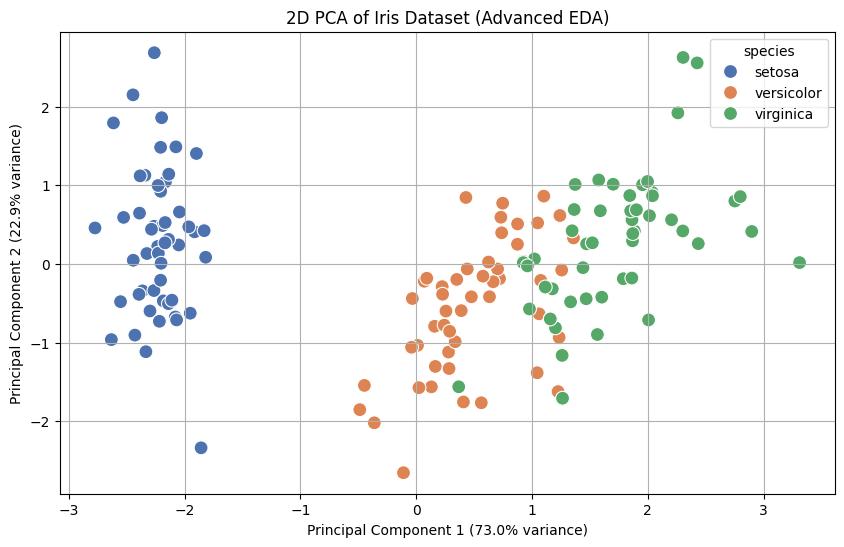

In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Dataset Load Karna
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = [iris.target_names[i] for i in iris.target]

print("Dataset Loaded. Shape:", df.shape)

# 2. Advanced Feature Engineering (Data Scaling)
features = iris.feature_names
x = df.loc[:, features].values
x_scaled = StandardScaler().fit_transform(x)

# 3. Dimensionality Reduction (PCA for 2D Visualization)
pca = PCA(n_components=2)
principal_components = pca.fit_transform(x_scaled)
pca_df = pd.DataFrame(data=principal_components, columns=['PC1', 'PC2'])
pca_df['species'] = df['species']

# 4. IIT-Level Visualization
plt.figure(figsize=(10, 6))
sns.scatterplot(x='PC1', y='PC2', hue='species', data=pca_df, palette='deep', s=100)
plt.title('2D PCA of Iris Dataset (Advanced EDA)')
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
plt.grid(True)
plt.show()

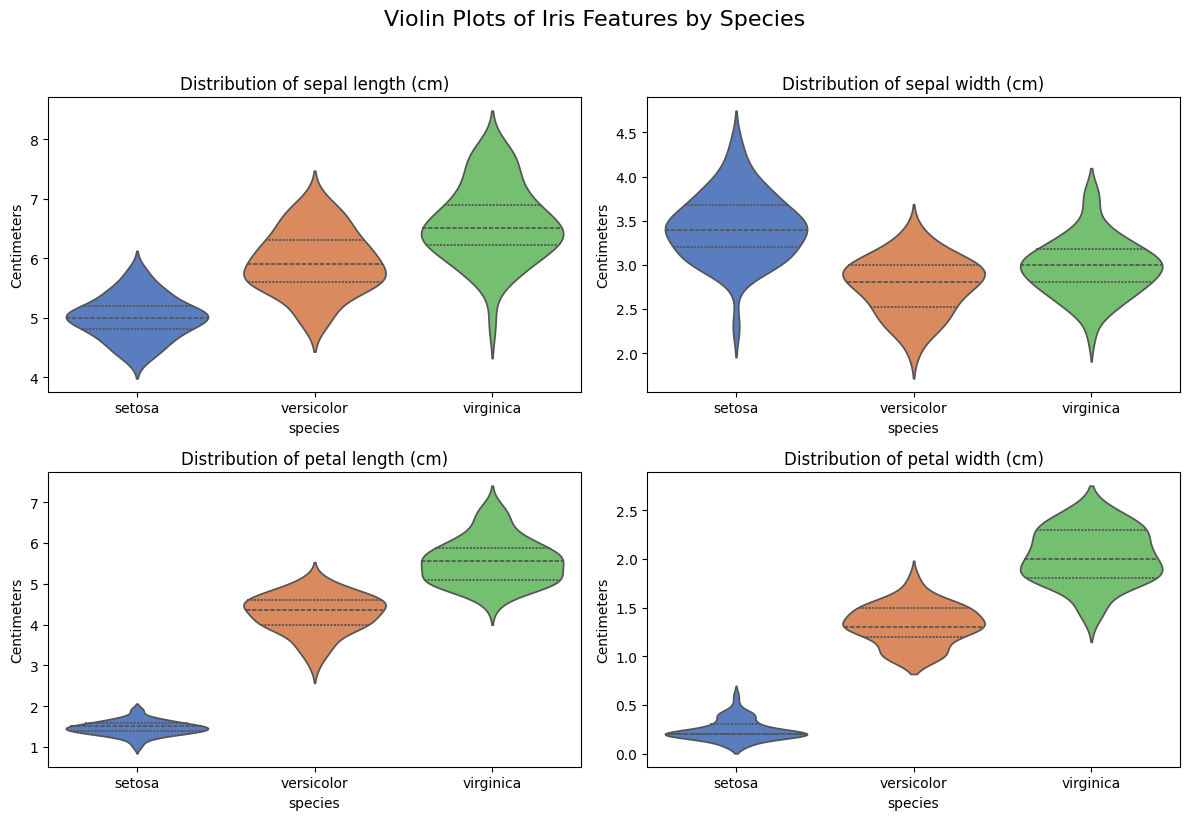

In [10]:
# 5. Advanced Statistical Distribution (Violin Plots) - FIXED
plt.figure(figsize=(12, 8))
for i, feature in enumerate(features):
    plt.subplot(2, 2, i+1)
    # Fix: Added hue='species' and legend=False to avoid FutureWarning
    sns.violinplot(x='species', y=feature, data=df, hue='species', palette='muted', inner="quartile", legend=False)
    plt.title(f'Distribution of {feature}')
    plt.ylabel('Centimeters')

plt.suptitle('Violin Plots of Iris Features by Species', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

In [11]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# 1. Define Features (X) and Target (y)
X = df.drop('species', axis=1)
y = df['species']

# 2. Train-Test Split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Initialize Random Forest Model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# 4. Stratified 5-Fold Cross Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(rf_model, X, y, cv=cv, scoring='accuracy')

print(f"Cross-Validation Accuracy Scores: {np.round(cv_scores, 4)}")
print(f"Mean CV Accuracy: {cv_scores.mean() * 100:.2f}% (+/- {cv_scores.std() * 200:.2f}%)")

# 5. Train Final Model and Predict
rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)

# 6. Evaluation Metrics
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred))

Cross-Validation Accuracy Scores: [0.9667 0.9667 0.9333 0.9667 0.9   ]
Mean CV Accuracy: 94.67% (+/- 5.33%)

--- Classification Report ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



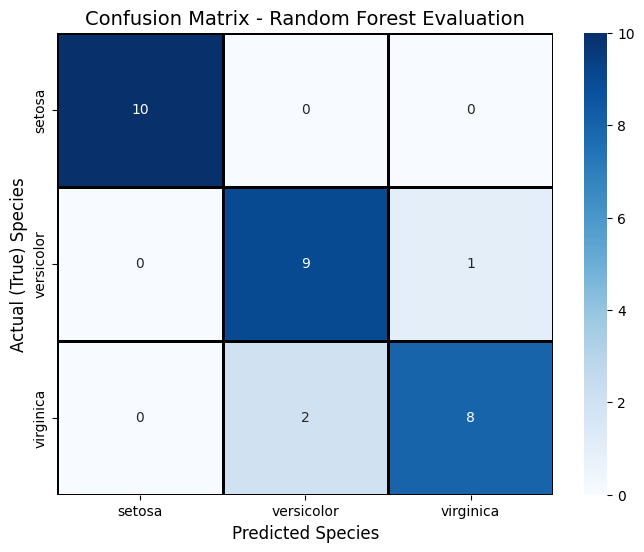

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# IIT-Level Confusion Matrix Visualization
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=rf_model.classes_, 
            yticklabels=rf_model.classes_,
            linewidths=1, linecolor='black')

plt.title('Confusion Matrix - Random Forest Evaluation', fontsize=14)
plt.xlabel('Predicted Species', fontsize=12)
plt.ylabel('Actual (True) Species', fontsize=12)
plt.show()

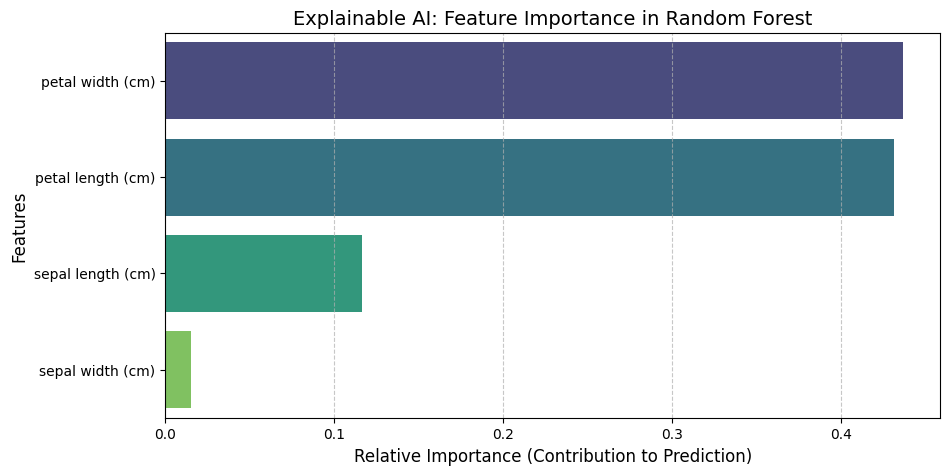

In [13]:
# 7. Model Explainability - Feature Importance
importance = rf_model.feature_importances_
feature_imp_df = pd.DataFrame({'Feature': features, 'Importance': importance}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 5))
# Added hue and legend=False to keep it clean and warning-free
sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='viridis', hue='Feature', legend=False)

plt.title('Explainable AI: Feature Importance in Random Forest', fontsize=14)
plt.xlabel('Relative Importance (Contribution to Prediction)', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

In [15]:
import joblib
import warnings
warnings.filterwarnings('ignore') # To suppress valid input warnings during prediction

# 1. Export the Model (Saving it to your hard drive)
model_filename = 'iris_rf_model.joblib'
joblib.dump(rf_model, model_filename)
print(f"✅ Model successfully saved as '{model_filename}'\n")

# 2. Production-Ready Inference Function (API Style)
def predict_new_flower(sepal_length, sepal_width, petal_length, petal_width):
    """
    Yeh function production environment mein use hoga.
    User se 4 measurements lega aur species + confidence score return karega.
    """
    # Load the saved model
    loaded_model = joblib.load(model_filename)
    
    # Format input data
    input_data = [[sepal_length, sepal_width, petal_length, petal_width]]
    
    # Make prediction and calculate probability (confidence)
    prediction = loaded_model.predict(input_data)[0]
    confidence = loaded_model.predict_proba(input_data).max() * 100
    
    return prediction, confidence

# 3. Let's test our Production Pipeline with dummy data
# Values: Sepal Length=5.1, Sepal Width=3.5, Petal Length=1.4, Petal Width=0.2 (Typical Setosa)
species, conf = predict_new_flower(5.1, 3.5, 1.4, 0.2)

print("--- Production API Test ---")
print(f"Predicted Species: {species.upper()}")
print(f"AI Confidence Score: {conf:.2f}%")

✅ Model successfully saved as 'iris_rf_model.joblib'

--- Production API Test ---
Predicted Species: SETOSA
AI Confidence Score: 100.00%


In [17]:
%%writefile app.py
import streamlit as st
import joblib
import numpy as np

# Load the saved model
@st.cache_resource
def load_model():
    return joblib.load('iris_rf_model.joblib')

model = load_model()

st.title("🌸 Iris Flower Classifier (IIT-Level AI)")
st.write("Enter flower measurements to predict its species.")

# Sliders for user input
sepal_length = st.slider("Sepal Length (cm)", 4.0, 8.0, 5.1)
sepal_width = st.slider("Sepal Width (cm)", 2.0, 4.5, 3.5)
petal_length = st.slider("Petal Length (cm)", 1.0, 7.0, 1.4)
petal_width = st.slider("Petal Width (cm)", 0.1, 2.5, 0.2)

if st.button("Predict Species"):
    input_data = np.array([[sepal_length, sepal_width, petal_length, petal_width]])
    prediction = model.predict(input_data)[0]
    confidence = np.max(model.predict_proba(input_data)) * 100
    
    st.success(f"Predicted Species: **{prediction.upper()}**")
    st.info(f"AI Confidence Score: **{confidence:.2f}%**")

Overwriting app.py


In [18]:
%%writefile app.py
import streamlit as st
import joblib
import numpy as np
import time

# Load the saved model
@st.cache_resource
def load_model():
    return joblib.load('iris_rf_model.joblib')

model = load_model()

# Image URLs for the 3 species
species_images = {
    'setosa': 'https://upload.wikimedia.org/wikipedia/commons/a/a7/Irissetosa1.jpg',
    'versicolor': 'https://upload.wikimedia.org/wikipedia/commons/4/41/Iris_versicolor_3.jpg',
    'virginica': 'https://upload.wikimedia.org/wikipedia/commons/f/f8/Iris_virginica_2.jpg'
}

st.title("🌸 Iris Flower Classifier (IIT-Level AI)")
st.write("Enter flower measurements to predict its species.")

# Sliders for user input
sepal_length = st.slider("Sepal Length (cm)", 4.0, 8.0, 5.1)
sepal_width = st.slider("Sepal Width (cm)", 2.0, 4.5, 3.5)
petal_length = st.slider("Petal Length (cm)", 1.0, 7.0, 1.4)
petal_width = st.slider("Petal Width (cm)", 0.1, 2.5, 0.2)

# Placeholder for dynamic image gallery
gallery_placeholder = st.empty()

def show_images(predicted_species=None):
    cols = st.columns(3)
    for idx, (species, img_url) in enumerate(species_images.items()):
        with cols[idx]:
            if predicted_species is None:
                # Default state: Normal images
                st.markdown(f'<div style="text-align:center"><img src="{img_url}" width="100%" style="border-radius:10px;"><br><b>{species.capitalize()}</b></div>', unsafe_allow_html=True)
            elif species == predicted_species:
                # Highlighted state: Correct prediction (Green border + Glow)
                st.markdown(f'<div style="text-align:center"><img src="{img_url}" width="100%" style="border: 4px solid #4CAF50; border-radius:10px; box-shadow: 0px 0px 15px #4CAF50;"><br><b style="color:#4CAF50">{species.capitalize()}</b></div>', unsafe_allow_html=True)
            else:
                # Blurred state: Incorrect predictions
                st.markdown(f'<div style="text-align:center"><img src="{img_url}" width="100%" style="border-radius:10px; filter: blur(4px) grayscale(80%); opacity: 0.4;"><br><b style="color:gray">{species.capitalize()}</b></div>', unsafe_allow_html=True)

# Show normal images initially
with gallery_placeholder.container():
    show_images()

if st.button("Predict Species"):
    # UI Animation effect (Spinner)
    with st.spinner("AI is analyzing the physical characteristics... 🧠"):
        time.sleep(1.5) # 1.5 seconds ka dramatic loading effect
        
    input_data = np.array([[sepal_length, sepal_width, petal_length, petal_width]])
    prediction = model.predict(input_data)[0].lower()
    confidence = np.max(model.predict_proba(input_data)) * 100
    
    # Update gallery: blur wrong ones, highlight correct one
    gallery_placeholder.empty() # Clear old images
    with gallery_placeholder.container():
        show_images(prediction)
        
    st.success(f"Predicted Species: **{prediction.upper()}**")
    st.info(f"AI Confidence Score: **{confidence:.2f}%**")

Overwriting app.py
